<h1>Marvel comics data analysis</h1>

<p>We will construct a graph from the processed data and observe intereting properties about it</p>

In [3]:
import csv


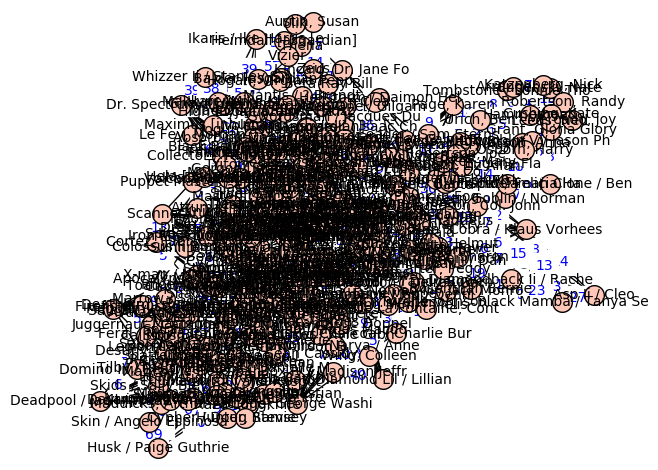

In [4]:
G=Graph(weighted=True)
csv_path='../data/processed/marvel/marvel_edges_clean.csv'

nodes=set()
edges=set()


with open(csv_path,mode='r') as f:
    lines=csv.reader(f)
    next(lines) #Skip headers
    for l in lines:
        source:str=l[0]
        target:str=l[1]
        weight:int=int(l[2])
        
        nodes.add(source)
        nodes.add(target)
        edges.add((source,target,weight))
        

G.add_vertices(nodes)
G.add_edges(edges)

        
G.plot(edge_labels=True)

            
            
    


<h1>Estudio de propiedades</h1>

<h4>Personaje con el mayor número de interacciones</h2>

In [1]:
def number_of_interactions(character:str)->int:
    res=0
    for e in G.edges():
        if character==e[0] or character==e[1]: #Character is source or target
            res+=e[2]
    return res
    


max_interactions_node=max(G.vertices(),key=number_of_interactions)

show(max_interactions_node)

NameError: name 'G' is not defined

<h4>Grado y grado ponderado</h4>
<p>Con quién habla cada personaje y cuanto</p>


In [7]:
def degreeOfAll():
    
    grado = dict(G.degree(labels=True))

    # Grado ponderado: suma de los pesos de sus aristas
    pond = {v: sum(w for (_, _, w) in G.edges_incident(v, labels=True)) for v in G}
    
    return (grado,pond)

res=degreeOfAll()
grado=res[0]
ponderado=res[1]

print(grado)

print("################################################################################")
print(ponderado)
        
    


{'Gambit / Remy Lebeau': 121, 'Hammerhead': 19, 'Crystal [inhuman]': 114, 'Lyja Lazerfist [skru': 32, 'Hellcat / Patsy Walker': 62, 'Havok / Alex Summers': 124, 'Forge': 73, 'Cypher / Doug Ramsey': 41, 'Dr. Spectrum / Joseph': 15, 'Psylocke / Elisabeth B': 132, 'Polaris / Lorna Dane': 111, 'Hodge, Cameron': 27, 'Gorgon [inhuman]': 44, 'Warlock Ii / Adam Warl': 75, 'She-hulk / Jennifer Wa': 178, 'Maddicks, Arthur Art': 26, 'Jocasta': 27, 'Wizard / Bentley Wittm': 29, 'De La Fontaine, Cont': 22, 'Puppet Master / Philli': 25, 'Bishop  / ': 68, 'Wasp / Janet Van Dyne': 188, 'Mockingbird / Dr. Barb': 62, 'Dugan, Timothy Aloyi': 48, 'Dazzler Ii / Allison B': 52, 'Norriss, Sister Barb': 61, 'Sunspot / Roberto Daco': 82, 'Legion Ii / David Hall': 29, 'Ghost Rider Ii / Johnn': 27, 'Thing / Benjamin J. Gr': 214, 'Austin, Susan': 17, 'Lockheed': 50, 'Vanguard / Nicolai Kry': 25, 'Uatu': 82, 'Firestar / Angelica Jo': 91, 'Hawk': 170, 'Doc Samson / Dr. Leona': 40, 'Speedball / Robbie Bal': 77, 'Iro

<h4>Intermediación(betweenes)</h4>
<p>Quien actúa de puente entre grupos </p>

In [13]:
import networkx as nx

# Copia del grafo en networkx con peso y distancia (1/peso)
Gn = nx.DiGraph() if G.is_directed() else nx.Graph()
for u, v, w in G.edges(labels=True):
    Gn.add_edge(u, v, peso=w, dist=1 / w)

inter   = nx.betweenness_centrality(Gn)                  # sin pesos, normalizada
inter_w = nx.betweenness_centrality(Gn, weight="dist")   # ponderada

filas = sorted(
    [(v, round(inter[v], 3), round(inter_w[v], 3)) for v in G],
    key=lambda t: -t[1])
table([["personaje", "intermediación", "inter. ponderada"]] + filas, header_row=True)

personaje,intermediación,inter. ponderada
Captain America,,
Spider-man / Peter Parker,,
Wolverine / Logan,,
Beast / Henry &hank& P,,
Thor / Dr. Donald Blak,,
Vision,,
Thing / Benjamin J. Gr,,
Iron Man / Tony Stark,,
Cyclops / Scott Summer,,
Mr. Fantastic / Reed R,,


<p>La intermediación de un personaje v es la fracción de caminos mínimos entre todos los pares de personajes que pasan por v</p>
<p>Que personajes como Zeus tengan un betweenes de 0 implica que no está en nigún camino mínimo entre dos personajes</p>

<h4>Autovector (eigenvector)</h4>
<p>Quién está conectado con los personajes importantes</p>

In [14]:
import networkx as nx

# Sin pesos (solo estructura) y con pesos (fuerza de las interacciones)
auto   = nx.eigenvector_centrality(Gn, max_iter=1000)
auto_w = nx.eigenvector_centrality(Gn, weight="peso", max_iter=1000)

# Reescalo para que el máximo valga 1 y sea más fácil de leer
m, mw = max(auto.values()), max(auto_w.values())
filas = sorted(
    [(v, round(auto[v] / m, 3), round(auto_w[v] / mw, 3)) for v in G],
    key=lambda t: -t[1])
table([["personaje", "autovector", "autovector pond."]] + filas, header_row=True)

personaje,autovector,autovector pond.
Captain America,,
Wolverine / Logan,,
Thing / Benjamin J. Gr,,
Vision,,
Beast / Henry &hank& P,,
Spider-man / Peter Parker,,
Human Torch / Johnny S,,
Cyclops / Scott Summer,,
Invisible Woman / Sue,,
Scarlet Witch / Wanda,,


<p>Valor alto: el personaje está conectado con otros que también tienen valores altos. Es parte del núcleo de la red.</p>
<p>Valor bajo: está en la periferia, o conectado con personajes periféricos </p>

<h4>Cercanía (closeness)</h4>
<p> quién llega más rápido a todos los demás.</p>

In [15]:
import networkx as nx

cerc   = nx.closeness_centrality(Gn)                     # sin pesos (saltos)
cerc_w = nx.closeness_centrality(Gn, distance="dist")    # ponderada (dist = 1/peso)

filas = sorted(
    [(v, round(cerc[v], 3), round(cerc_w[v], 3)) for v in G],
    key=lambda t: -t[1])
table([["personaje", "cercanía", "cercanía pond."]] + filas, header_row=True)

personaje,cercanía,cercanía pond.
Captain America,,
Wolverine / Logan,,
Spider-man / Peter Parker,,
Thing / Benjamin J. Gr,,
Vision,,
Thor / Dr. Donald Blak,,
Beast / Henry &hank& P,,
Iron Man / Tony Stark,,
Mr. Fantastic / Reed R,,
Cyclops / Scott Summer,,


<h4>Número de nodos, aristas, densidad y componentes conexas.</h4>

In [16]:
n = G.order()          # número de nodos
m = G.size()           # número de aristas
dens = G.density()     # densidad

print("Nodos:", n)
print("Aristas:", m)
print("Densidad:", round(float(dens), 4))

Nodos: 327
Aristas: 9891
Densidad: 0.1856


In [17]:
comps = G.connected_components()          # lista de listas de nodos
print("Componentes conexas:", len(comps))
print("¿Conexo?", G.is_connected())

filas = sorted([(i + 1, len(c)) for i, c in enumerate(comps)], key=lambda t: -t[1])
table([["componente", "nº de nodos"]] + filas, header_row=True)

Componentes conexas: 1
¿Conexo? True


componente,nº de nodos
,


<h4>Comunidades</h4>
<p>¿salen grupos coherentes con la trama (Naboo, Jedi, Federación de Comercio, Tatooine)?</p>

In [24]:
pesos = [d["peso"] for _, _, d in Gu.edges(data=True)]
print("Aristas Gu:", Gu.number_of_edges(),
      "| nodos con alguna arista:", sum(1 for v in Gu if Gu.degree(v) > 0))
if pesos:
    print("Pesos: mín", min(pesos), "máx", max(pesos))
print("Componentes (mayores):",
      sorted((len(c) for c in nx.connected_components(Gu)), reverse=True)[:8])

# Sin pesos
sin = list(nxc.greedy_modularity_communities(Gu))
print("CNM sin pesos:", len(sin), "| mayores:", sorted(map(len, sin), reverse=True)[:8],
      "| Q =", round(nxc.modularity(Gu, sin), 3))

# Otro algoritmo que sí existe en networkx 2.2
lp = list(nxc.label_propagation_communities(Gu))
print("Propagación de etiquetas:", len(lp), "| mayores:", sorted(map(len, lp), reverse=True)[:8],
      "| Q =", round(nxc.modularity(Gu, lp), 3))

Aristas Gu: 9891 | nodos con alguna arista: 327
Pesos: mín 5.0 máx 744.0
Componentes (mayores): [327]
CNM sin pesos: 4 | mayores: [168, 116, 34, 9] | Q = 0.251
Propagación de etiquetas: 1 | mayores: [327] | Q = -0.0


In [25]:
import random

def _fase(g, k, m2, rnd):
    com = {u: u for u in g}
    tot = dict(k)
    mejora, movido = False, True
    while movido:
        movido = False
        orden = list(g); rnd.shuffle(orden)
        for u in orden:
            cu = com[u]
            w_com = {}
            for v, w in g[u].items():
                if v != u:
                    w_com[com[v]] = w_com.get(com[v], 0.0) + w
            tot[cu] -= k[u]
            mejor, mejor_g = cu, w_com.get(cu, 0.0) - tot[cu] * k[u] / m2
            for c, w in w_com.items():
                gan = w - tot[c] * k[u] / m2
                if gan > mejor_g + 1e-12:
                    mejor, mejor_g = c, gan
            tot[mejor] += k[u]
            com[u] = mejor
            if mejor != cu:
                movido = mejora = True
    return com, mejora

def louvain_pond(Gx, weight="peso", seed=42):
    rnd = random.Random(seed)
    g = {u: {v: d.get(weight, 1.0) for v, d in Gx[u].items() if v != u} for u in Gx}
    miembros = {u: [u] for u in g}
    m2 = sum(w for nb in g.values() for w in nb.values())
    while True:
        k = {u: sum(nb.values()) for u, nb in g.items()}
        com, mejora = _fase(g, k, m2, rnd)
        if not mejora:
            break
        ids = {c: i for i, c in enumerate(dict.fromkeys(com.values()))}
        ng = {i: {} for i in ids.values()}
        for u, nb in g.items():
            for v, w in nb.items():
                a, b = ids[com[u]], ids[com[v]]
                ng[a][b] = ng[a].get(b, 0.0) + w
        nuevo = {i: [] for i in ids.values()}
        for u, c in com.items():
            nuevo[ids[c]].extend(miembros[u])
        g, miembros = ng, nuevo
    return list(miembros.values())

def modularidad(Gx, comunidades, weight="peso"):
    m2 = 2 * sum(d[weight] for _, _, d in Gx.edges(data=True))
    k = dict(Gx.degree(weight=weight))
    Q = 0.0
    for c in comunidades:
        c = set(c)
        interno = sum(d[weight] for _, _, d in Gx.subgraph(c).edges(data=True))
        Q += 2 * interno / m2 - (sum(k[u] for u in c) / m2) ** 2
    return Q

# Varias semillas: me quedo con la de mayor modularidad
mejores = max((louvain_pond(Gu, seed=s) for s in range(10)),
              key=lambda p: modularidad(Gu, p))
comunidades = sorted(mejores, key=len, reverse=True)

print("Nº de comunidades:", len(comunidades))
print("Modularidad ponderada:", round(modularidad(Gu, comunidades), 3))
print("Tamaños:", [len(c) for c in comunidades])

fuerza = dict(Gu.degree(weight="peso"))
filas = [(i + 1, len(c), ", ".join(map(str, sorted(c, key=lambda v: -fuerza[v])[:8])))
         for i, c in enumerate(comunidades[:10])]
table([["comunidad", "tamaño", "personajes con más peso"]] + filas, header_row=True)

Nº de comunidades: 7
Modularidad ponderada: 0.436
Tamaños: [94, 86, 41, 32, 29, 27, 18]


comunidad,tamaño,personajes con más peso
,,"Wolverine / Logan, Beast / Henry &hank& P, Cyclops / Scott Summer, Storm / Ororo Munroe S, Professor X / Charles, Colossus Ii / Peter Ra, Marvel Girl / Jean Grey, Angel / Warren Kenneth"
,,"Captain America, Iron Man / Tony Stark, Vision, Scarlet Witch / Wanda, Wasp / Janet Van Dyne, Hawk, Ant-man / Dr. Henry J., Wonder Man / Simon Wil"
,,"Spider-man / Peter Parker, Jameson, J. Jonah, Daredevil / Matt Murdo, Watson-parker, Mary, Robertson, Joe, Parker, May, Leeds, Betty Brant, Thompson, Eugene Fla"
,,"Nova / Richard Rider, Sasquatch / Walter Lan, Hudson, Heather, Firestar / Angelica Jo, Namorita / Nita Prenti, Puck / Eugene Milton J, Shaman / Michael Twoyo, Northstar / Jean-paul"
,,"Thing / Benjamin J. Gr, Human Torch / Johnny S, Mr. Fantastic / Reed R, Invisible Woman / Sue, Crystal [inhuman], Dr. Doom / Victor Von, Richards, Franklin B, Silver Surfer / Norrin"
,,"Thor / Dr. Donald Blak, Odin [asgardian], Hogun [asgardian], Fandral [asgardian], Volstagg, Thunderstrike / Eric K, Loki [asgardian], Balder [asgardian]"
,,"Hulk / Dr. Robert Bruce Banner, Dr. Strange / Stephen, Jones, Richard Milho, Norriss, Sister Barb, Hellcat / Patsy Walker, Banner, Betty Ross T, Cage, Luke / Carl Luca, Iron Fist / Daniel Ran"


<h4>Camino medio y diámetro (grados de separación)</h4>

In [26]:
print("Diámetro:", G.diameter())
print("Camino medio:", G.average_distance())

Diámetro: 3
Camino medio: 99833/53301


<p>El diámetro es la mayor distancia que hay entre dos personajes cualesquiera de la red</p>

<p>El camino medio es la distancia media entre todos los pares de personajes</p>

<h4>Resumen y Comparación</h4>


In [28]:
import networkx as nx

for u, v, d in Gu.edges(data=True):
    d["dist"] = 1.0 / d["peso"]            # peso alto = más cerca

metricas = {
    "grado":            dict(Gu.degree()),
    "grado pond.":      dict(Gu.degree(weight="peso")),
    "cercanía":         nx.closeness_centrality(Gu),
    "cercanía pond.":   nx.closeness_centrality(Gu, distance="dist"),
    "intermediación":   nx.betweenness_centrality(Gu),
    "inter. pond.":     nx.betweenness_centrality(Gu, weight="dist"),
    "autovector":       nx.eigenvector_centrality_numpy(Gu),
    "autovector pond.": nx.eigenvector_centrality_numpy(Gu, weight="peso"),
}

N = 10
nombres = list(metricas)
tops = {m: sorted(d, key=lambda v: -d[v])[:N] for m, d in metricas.items()}
for m, d in metricas.items():
    top = sorted(d, key=lambda v: -d[v])[:N]
    print(m.upper())
    show(table([["#", "personaje", "valor"]] +
               [(i + 1, v, round(d[v], 4)) for i, v in enumerate(top)],
               header_row=True))


GRADO


#,personaje,valor
,Captain America,
,Wolverine / Logan,
,Spider-man / Peter Parker,
,Thing / Benjamin J. Gr,
,Vision,
,Thor / Dr. Donald Blak,
,Beast / Henry &hank& P,
,Iron Man / Tony Stark,
,Mr. Fantastic / Reed R,
,Cyclops / Scott Summer,


GRADO POND.


#,personaje,valor
,Captain America,
,Spider-man / Peter Parker,
,Thor / Dr. Donald Blak,
,Thing / Benjamin J. Gr,
,Iron Man / Tony Stark,
,Human Torch / Johnny S,
,Vision,
,Scarlet Witch / Wanda,
,Wolverine / Logan,
,Mr. Fantastic / Reed R,


CERCANÍA


#,personaje,valor
,Captain America,
,Wolverine / Logan,
,Spider-man / Peter Parker,
,Thing / Benjamin J. Gr,
,Vision,
,Thor / Dr. Donald Blak,
,Beast / Henry &hank& P,
,Iron Man / Tony Stark,
,Mr. Fantastic / Reed R,
,Cyclops / Scott Summer,


... (6 outputs left out)

AUTOVECTOR


#,personaje,valor
,Captain America,
,Wolverine / Logan,
,Thing / Benjamin J. Gr,
,Vision,
,Beast / Henry &hank& P,
,Spider-man / Peter Parker,
,Human Torch / Johnny S,
,Invisible Woman / Sue,
,Cyclops / Scott Summer,
,Scarlet Witch / Wanda,


AUTOVECTOR POND.


#,personaje,valor
,Captain America,
,Thing / Benjamin J. Gr,
,Human Torch / Johnny S,
,Mr. Fantastic / Reed R,
,Iron Man / Tony Stark,
,Invisible Woman / Sue,
,Scarlet Witch / Wanda,
,Vision,
,Thor / Dr. Donald Blak,
,Wasp / Janet Van Dyne,
